In [ ]:
import numpy as np
from scipy import stats, special
from scipy.optimize import curve_fit
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
np.random.seed(42)

Normal distribution

Text(0, 0.5, 'Density')

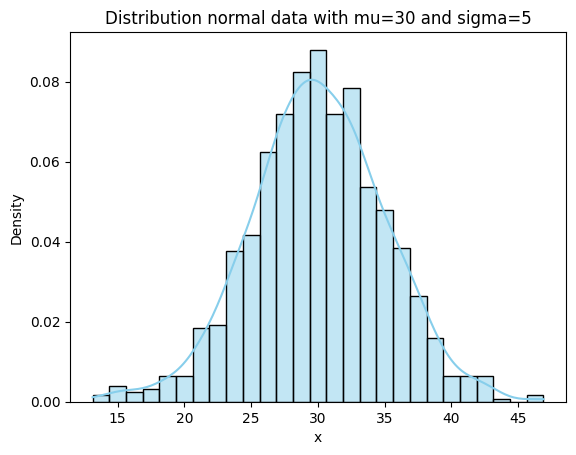

In [ ]:
mu, sigma = 30, 5
normal_data = stats.norm(mu, sigma).rvs(1000)
sns.histplot(normal_data, kde=True, color='skyblue', stat="density")
plt.title(f"Distribution normal data with mu={mu} and sigma={sigma}")
plt.xlabel("x")
plt.ylabel("Density")

Exponential data

Text(0, 0.5, 'Density')

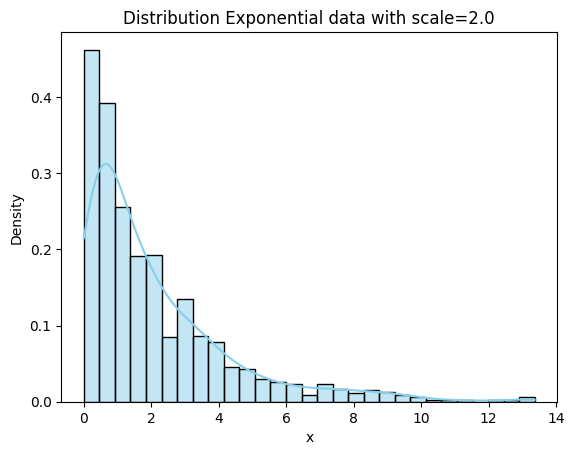

In [ ]:
rate = 0.5
scale = 1/rate
exponential_data = stats.expon(scale=scale).rvs(1000)
sns.histplot(exponential_data, kde=True, color='skyblue', stat="density")
plt.title(f"Distribution Exponential data with scale={scale}")
plt.xlabel("x")
plt.ylabel("Density")

Gamma distribution

<Axes: ylabel='Density'>

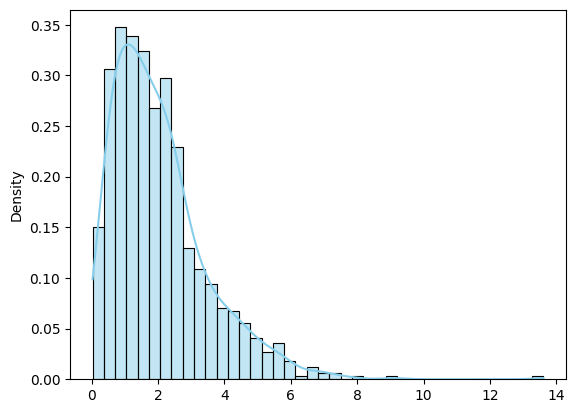

In [ ]:
gamma_data = stats.gamma(a=2, scale=1).rvs(1000)
sns.histplot(gamma_data, kde=True, color='skyblue', stat="density")

Power Law distribution

<Axes: ylabel='Density'>

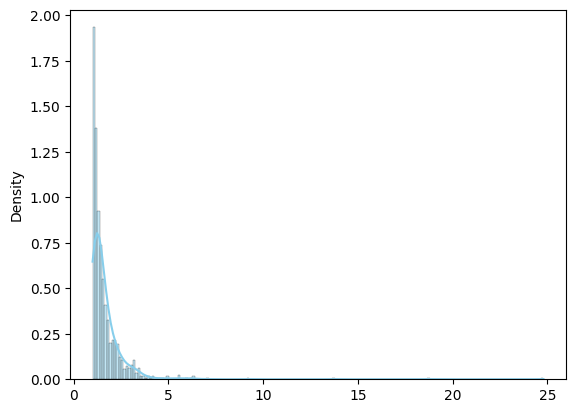

In [ ]:
# Parameters
alpha = 2.5  # Scaling exponent
x_min = 1.0  # Minimum value

powerlaw_data = stats.pareto.rvs(b=alpha, loc=0, scale=x_min, size=1000)

sns.histplot(powerlaw_data, kde=True, color='skyblue', stat="density")

Save distributions to csv dataframe

In [ ]:
df = pd.DataFrame({
    'Normal': normal_data,
    'Exponential': exponential_data,
    'Gamma': gamma_data,
    'Unknown': powerlaw_data
})
df.to_csv('Tom_distributions.csv', index=False)

Guessing paramters using scipy.stats.fit

In [ ]:
mu_guess, std_guess = stats.norm.fit(normal_data)
print(f"Estimated Mean: {mu_guess:.2f}")
print(f"Estimated Std: {std_guess:.2f}")

Estimated Mean: 29.93
Estimated Std: 5.03


In [ ]:
scale_guess = stats.expon.fit(exponential_data)
print(f"Estimated Scale: {scale_guess[1]:.2f}")

Estimated Scale: 2.06


In [ ]:
a, loc, scale = stats.gamma.fit(gamma_data)
print(f"Estimated a: {a:.2f}")
print(f"Estimated loc: {loc:.2f}")
print(f"Estimated scale: {scale:.2f}")

Estimated a: 2.02
Estimated loc: -0.01
Estimated scale: 1.01


In [ ]:
a_fit, loc_fit, xmin_fit = stats.pareto.fit(powerlaw_data, floc=0)

# Print the estimated parameters
print(f"Estimated alpha: {a_fit:.3f}")
print(f"Estimated x_min: {xmin_fit:.3f}")


Estimated alpha: 2.489
Estimated x_min: 1.001


Analyzing Gabi's distributions

In [ ]:
df_gabi = pd.read_csv("Gabi_distributions.csv")
print(df_gabi.head())
df_gabi.columns


   Unnamed: 0  Distribution 1  Distribution 2  Distribution 3
0           0       66.837216              65       73.683866
1           1       72.099195              66       75.139107
2           2       62.230179              67       71.046371
3           3       74.460990              71       71.657739
4           4       64.870805              65       70.975986


Index(['Unnamed: 0', 'Distribution 1', 'Distribution 2', 'Distribution 3'], dtype='object')

In [ ]:
samp_1 = np.array(df_gabi['Distribution 1'])
samp_2 = np.array(df_gabi['Distribution 2'])
samp_3 = np.array(df_gabi['Distribution 3'])

Normal distribution - mean 70, std 5

<Axes: ylabel='Density'>

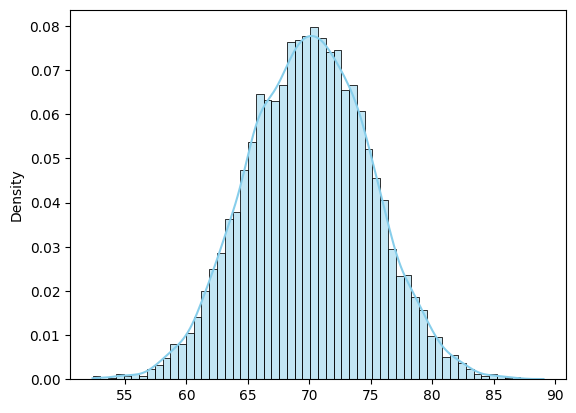

In [ ]:
sns.histplot(samp_1, kde=True, color='skyblue', stat="density")

In [ ]:
mu_guess, std_guess = stats.norm.fit(samp_1)
print(f"Estimated Mean: {mu_guess:.2f}")
print(f"Estimated Std: {std_guess:.2f}")

Estimated Mean: 70.02
Estimated Std: 4.95


Poisson distribution - mean 70, std 8.3

<Axes: ylabel='Density'>

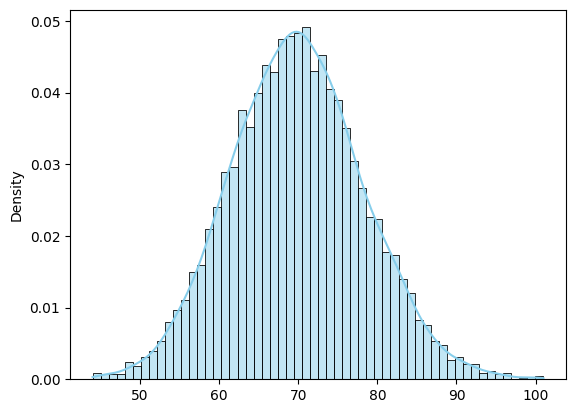

In [ ]:
sns.histplot(samp_2, kde=True, color='skyblue', stat="density")

In [ ]:
lambda_guess = np.mean(samp_2)

print(f"Estimated Mean: {lambda_guess:.2f}")
print(f"Estimated Std: {np.sqrt(lambda_guess):.2f}")

Estimated Mean: 69.90
Estimated Std: 8.36


Exponential distribution - location 70, lambda 0.2

<Axes: ylabel='Density'>

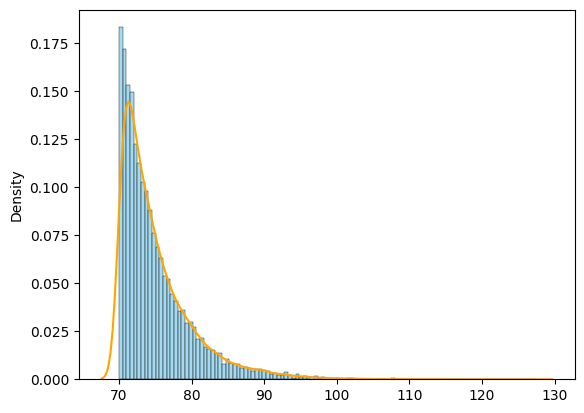

In [ ]:
ax = sns.histplot(samp_3, kde=False, color='skyblue', stat="density")
sns.kdeplot(samp_3, color='orange', ax=ax)


In [ ]:
loc_guess, scale_guess = stats.expon.fit(samp_3)

# Print the estimated parameters
print(f"Estimated location: {loc_guess:.3f}")
print(f"Estimated Mean: {scale_guess:.3f}")

Estimated location: 70.000
Estimated Mean: 5.052


Danny distributions

In [ ]:
df_danny = pd.read_csv("danny_distribution.csv")
print(df_danny.head())
df_danny.columns


                             complex gauss  poisson  exponential  \
0  (6.354149928547809+1.1587097693911208j)        7     0.105121   
1  (8.820124346373841+3.1878398422978593j)        7     0.341695   
2  (4.956988109516586+4.5010129388741476j)        3     0.026202   
3   (9.05719774220108+1.1193601233679726j)        5     0.123354   
4   (7.339020650563876+2.093051067632365j)       10     0.649462   

   Mystery distribution  
0                     3  
1                     5  
2                     3  
3                     4  
4                     2  


Index(['complex gauss', 'poisson', 'exponential', 'Mystery distribution'], dtype='object')

In [ ]:
samp_1 = np.array(df_danny['complex gauss'].astype(complex))
samp_2 = np.array(df_danny['poisson'])
samp_3 = np.array(df_danny['exponential'])
samp_4 = np.array(df_danny['Mystery distribution'])

Complex Normal distribution

<>:4: SyntaxWarning: invalid escape sequence '\R'
<>:5: SyntaxWarning: invalid escape sequence '\I'
<>:4: SyntaxWarning: invalid escape sequence '\R'
<>:5: SyntaxWarning: invalid escape sequence '\I'
/tmp/ipython-input-417/808699591.py:4: SyntaxWarning: invalid escape sequence '\R'
  plt.xlabel('Real Part ($\Re$)')
/tmp/ipython-input-417/808699591.py:5: SyntaxWarning: invalid escape sequence '\I'
  plt.ylabel('Imaginary Part ($\Im$)')


<Figure size 800x600 with 0 Axes>

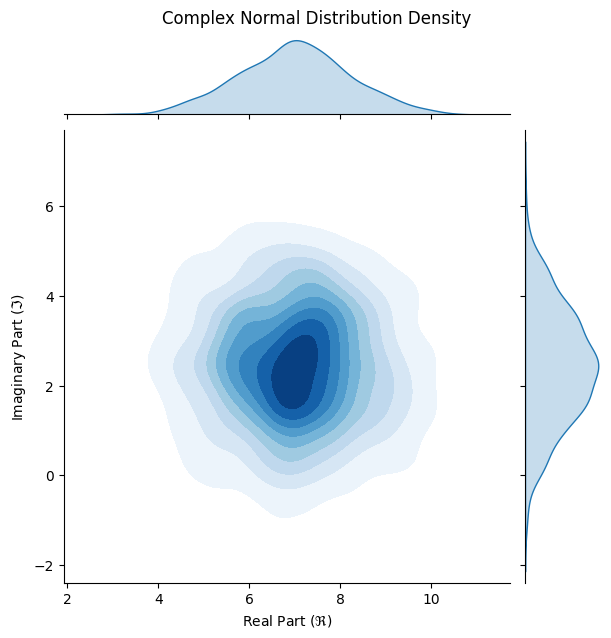

In [ ]:
plt.figure(figsize=(8, 6))
sns.jointplot(x=samp_1.real, y=samp_1.imag, kind="kde", cmap="Blues", fill=True)
plt.xlabel('Real Part ($\Re$)')
plt.ylabel('Imaginary Part ($\Im$)')
plt.suptitle('Complex Normal Distribution Density', y=1.02)
plt.show()

In [ ]:
mu_real, std_real = stats.norm.fit(samp_1.real)
mu_img, std_img = stats.norm.fit(samp_1.imag)
print(f"Real part Mean: {mu_real}")
print(f"Real part std: {std_real}")
print(f"Imag part Mean: {mu_img}")
print(f"Imag part std: {std_img}")

complex_mean = mu_real + 1j * mu_img
print(complex_mean)

Real part Mean: 6.996363851336518
Real part std: 1.2197181392022023
Imag part Mean: 2.436187322597659
Imag part std: 1.2840299757091347
(6.996363851336518+2.436187322597659j)


Poisson distribution - lambda 7

<Axes: ylabel='Density'>

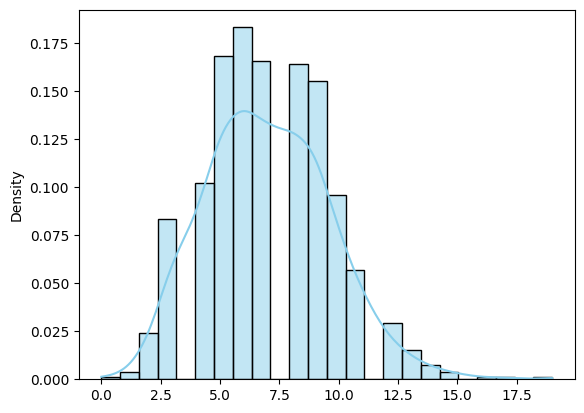

In [ ]:
sns.histplot(samp_2, kde=True, color='skyblue', stat="density")

In [ ]:
lambda_guess = np.mean(samp_2)

print(f"Estimated Mean: {lambda_guess:.2f}")
print(f"Estimated Std: {np.sqrt(lambda_guess):.2f}")

Estimated Mean: 7.03
Estimated Std: 2.65


Exponential distribution - location 0, lambda 0.2

<Axes: ylabel='Density'>

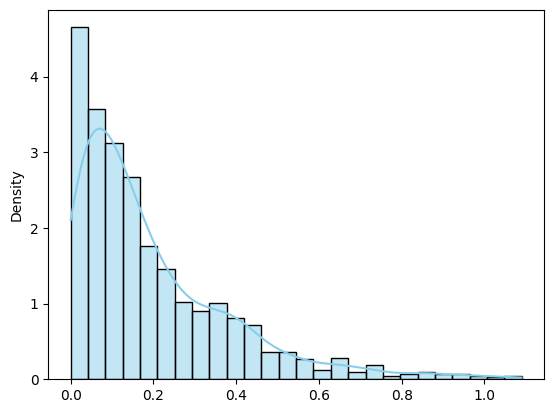

In [ ]:
sns.histplot(samp_3, kde=True, color='skyblue', stat="density")

In [ ]:
loc_guess, scale_guess = stats.expon.fit(samp_3)

# Print the estimated parameters
print(f"Estimated location: {loc_guess:.3f}")
print(f"Estimated Mean: {scale_guess:.3f}")

Estimated location: 0.000
Estimated Mean: 0.195


Unknown - Poisson distribution, lambda 3

<Axes: ylabel='Density'>

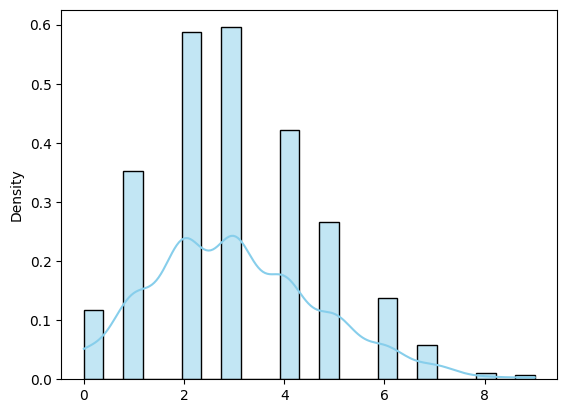

In [ ]:
sns.histplot(samp_4, kde=True, color='skyblue', stat="density")

In [ ]:
print(np.mean(samp_4))


3.021


Eliran's distributions

In [ ]:
df_eliran = pd.read_csv("eliran_distributions.csv")
print(df_eliran.head())
df_eliran.columns


   Unnamed: 0         t      chi2      beta   unknown
0           0  1.765716  0.669684  0.961576  8.425618
1           1 -0.888268  2.244101  0.611594  4.473281
2           2 -0.834918  6.481451  0.912616  4.017564
3           3  0.661523  2.017028  0.974178  3.090060
4           4 -0.753678  3.420983  0.781323  9.208438


Index(['Unnamed: 0', 't', 'chi2', 'beta', 'unknown'], dtype='object')

In [ ]:
samp_1 = np.array(df_eliran['t'])
samp_2 = np.array(df_eliran['chi2'])
samp_3 = np.array(df_eliran['beta'])
samp_4 = np.array(df_eliran['unknown'])

T distribution - mean 0 (unknown variance)

In [ ]:
df_est, loc_est, scale_est =  stats.t.fit(samp_1)
print(f"Estimated degrees of freedom (df): {df_est:.3f}")
print(f"Estimated location (loc): {loc_est:.3f}")
print(f"Estimated scale (scale): {scale_est:.3f}")

Estimated degrees of freedom (df): 2.783
Estimated location (loc): -0.039
Estimated scale (scale): 0.954


Chi-sqaue distribution - k 3

In [ ]:
print(f"Chi-Squared k (df): {stats.chi2.fit(samp_2)[0]}")

Chi-Squared k (df): 2.87242136059905


Beta distribution - alpha 5.7 beta 1

In [ ]:
print(f"Beta alpha and beta: {stats.beta.fit(samp_3)[:2]}")

Beta alpha and beta: (np.float64(5.744139435349028), np.float64(1.0055221500215863))


Unknown - Exponential distribution: location 3, lambda 2

<Axes: ylabel='Density'>

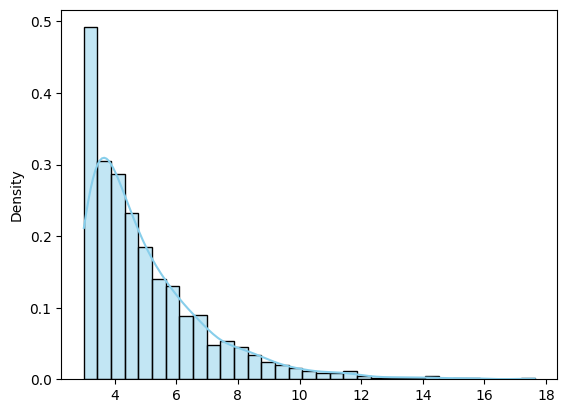

In [ ]:
sns.histplot(samp_4, kde=True, color='skyblue', stat="density")

In [ ]:
loc_mle, scale_mle = stats.expon.fit(samp_4)

# Print the estimated parameters
print(f"Estimated location: {loc_mle:.3f}")
print(f"Estimated Mean: {scale_mle:.3f}")

Estimated location: 3.000
Estimated Mean: 2.013


KL divergence to find the best theoretical distribution
1. Create the empirical distribution (P). Use a histogram to get x domain values
2. MLE
3. Calculate PDF of the fitted MLE on the bin centers
4. Calculate KL divergence
5. Sort KL divergences - Lower one is the best

In [ ]:
data = samp_3

hist, bin_edges = np.histogram(data, bins=50, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
pk = hist + 1e-10

candidates = [stats.norm, stats.beta, stats.powerlaw, stats.expon]
results = {}

for dist in candidates:

    params = dist.fit(data)


    qk = dist.pdf(bin_centers, *params) + 1e-10


    kl_div = stats.entropy(pk, qk)
    results[dist.name] = kl_div


best_fit = min(results, key=results.get)
print(f"KL Divergences: {results}")
print(f"The best fitting distribution is: {best_fit}")

KL Divergences: {'norm': np.float64(0.16736524167216452), 'beta': np.float64(0.022519599099819928), 'powerlaw': np.float64(0.02255803109650391), 'expon': np.float64(1.0405383136729482)}
The best fitting distribution is: beta


/usr/local/lib/python3.12/dist-packages/scipy/stats/_continuous_distns.py:796: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)


AIC to find the best theoretical distribution
1. MLE
2. Log-Likelihood of the MLE
3. Number of distibution's parameters (k)
4. Calculate AIC
5. Sort by AIC

In [ ]:
data = samp_3
candidates = [stats.norm, stats.beta, stats.powerlaw, stats.expon]
results = []

for dist in candidates:
    params = dist.fit(data)

    log_lik = dist.logpdf(data, *params).sum()

    k = len(params)

    aic = 2*k - 2*log_lik

    results.append((dist.name, aic, params))

results.sort(key=lambda x: x[1])
best_fit = min(results, key=lambda x: x[1])
print(results)
print(f"The best fitting distribution is: {best_fit[0]}")

[('expon', np.float64(-593.7371490516194), np.float64(1191.4742981032389), (0.1584909513113916, 0.6661350501813381)), ('norm', np.float64(481.5455056776425), np.float64(-959.091011355285), (np.float64(0.8246260014927297), np.float64(0.14949623971401851))), ('powerlaw', np.float64(755.881874577596), np.float64(-1505.763749155192), (np.float64(5.654558294611354), np.float64(-0.1658861717127981), np.float64(1.1658245397743139))), ('beta', np.float64(755.883175240157), np.float64(-1503.766350480314), (np.float64(5.744139435349028), np.float64(1.0055221500215863), np.float64(-0.1761859164213742), np.float64(1.176125455776063)))]
The best fitting distribution is: expon
